# kdmeufilme: análise dos dados e do recomendador

Este notebook acompanha o projeto **[kdmeufilme](https://horizontedigital.org/kdmeufilme)**, uma ferramenta que recebe um filme ou uma série favorita e recomenda 3 títulos parecidos.

O que você vai encontrar aqui:
1. **Os dados**: o que foi coletado do TMDB e como se distribui.
2. **Por que TF-IDF**: como o peso dos gêneros raros muda a comparação.
3. **O recomendador em ação**: recomendações para títulos conhecidos.
4. **Explicabilidade**: quanto cada sinal contribuiu para uma recomendação, e o que isso revelou.
5. **O filtro de franquias**: o antes e o depois.
6. **Conclusões e limitações**.

> Para rodar: gere os dados com `python pipeline/coletar_tmdb.py` e `python pipeline/preparar_dados.py` (veja o README). O notebook lê `dados/processados/titulos.json`.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "pipeline"))
import franquias
import recomendador as rec

with open(RAIZ / "dados" / "processados" / "titulos.json", encoding="utf-8") as f:
    titulos = json.load(f)
df = pd.DataFrame(titulos)
df["tipo"] = df["type"].map({"MOVIE": "Filme", "SHOW": "Série"})

# Estilo dos gráficos: marcas finas, grade discreta, sem moldura
LARANJA, AZUL, TINTA, TINTA_2 = "#EA580C", "#2563EB", "#18181B", "#52525B"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#D4D4D8", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#E4E4E7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "font.size": 10, "legend.frameon": False,
})
print(f"{len(df):,} títulos carregados".replace(",", "."))

15.979 títulos carregados


## 1. Os dados

Os dados vêm da API do **TMDB**: os 10 mil filmes e as 6 mil séries com mais votos. Depois da limpeza, ficaram estes:

In [2]:
resumo = df.groupby("tipo").agg(
    titulos=("id", "count"),
    ano_mais_antigo=("year", "min"),
    ano_mais_recente=("year", "max"),
    nota_media=("vote_average", "mean"),
    votos_medianos=("vote_count", "median"),
    sinopse_em_portugues=("overview_lang", lambda s: f"{(s == 'pt').mean():.0%}"),
    com_poster=("poster_path", lambda s: f"{s.notna().mean():.1%}"),
).round(1)
resumo

,titulos,ano_mais_antigo,ano_mais_recente,nota_media,votos_medianos,sinopse_em_portugues,com_poster
tipo,,,,,,,
Filme,9999,1895.0,2026.0,6.7,1019.0,98%,99.9%
Série,5980,1951.0,2026.0,7.4,168.0,91%,100.0%


### Quando os títulos foram lançados

O catálogo se concentra nos lançamentos recentes, principalmente no caso das séries. Isso é esperado, já que a seleção foi pelo número de votos, e títulos recentes têm mais votos online.

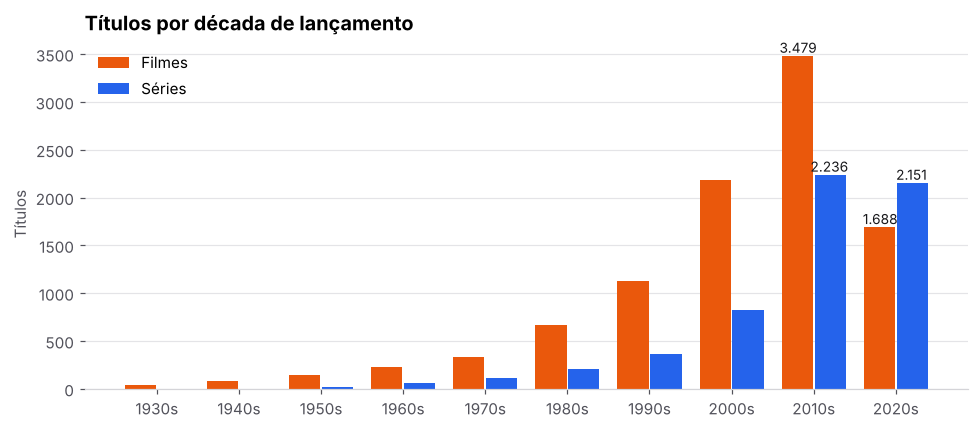

In [3]:
df["decada"] = (df["year"] // 10 * 10).astype("Int64")
por_decada = (df.dropna(subset=["decada"]).query("decada >= 1930")
              .groupby(["decada", "tipo"]).size().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(por_decada))
largura = 0.38
ax.bar(x - largura / 2 - 0.01, por_decada["Filme"], largura, color=LARANJA, label="Filmes")
ax.bar(x + largura / 2 + 0.01, por_decada["Série"], largura, color=AZUL, label="Séries")
ax.set_xticks(x, [f"{d}s" for d in por_decada.index])
ax.set_title("Títulos por década de lançamento")
ax.set_ylabel("Títulos")
ax.legend(loc="upper left")
for i, (f_, s_) in enumerate(zip(por_decada["Filme"], por_decada["Série"])):
    if i >= len(por_decada) - 2:
        ax.annotate(f"{f_:,}".replace(",", "."), (i - largura / 2, f_), ha="center", va="bottom", fontsize=9, color=TINTA)
        ax.annotate(f"{s_:,}".replace(",", "."), (i + largura / 2, s_), ha="center", va="bottom", fontsize=9, color=TINTA)
plt.tight_layout()
plt.show()

### Gêneros

Drama domina os dois catálogos. Na comparação entre títulos, esse é justamente o problema que o IDF resolve (seção 2): se quase todo mundo é "Drama", ter Drama em comum não diz muita coisa.

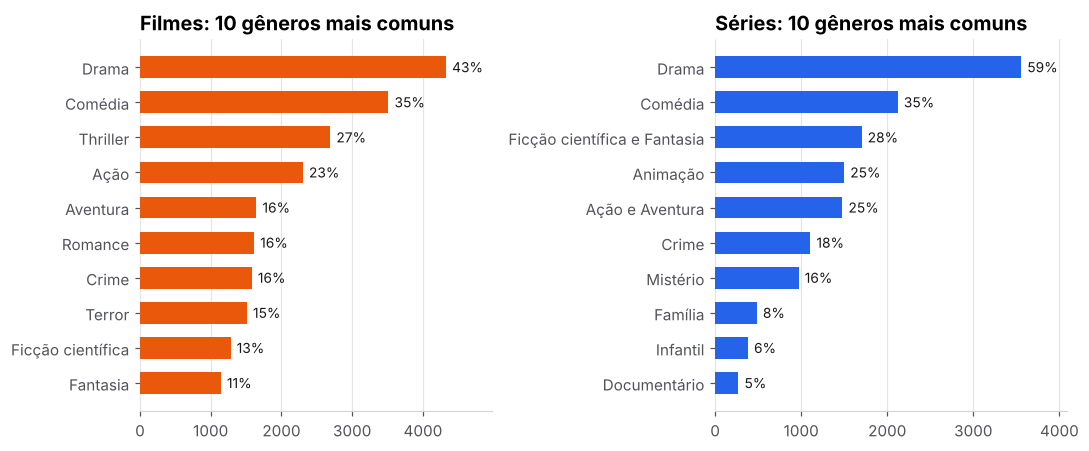

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (tipo, cor) in zip(eixos, [("Filme", LARANJA), ("Série", AZUL)]):
    contagem = Counter(g for gs in df.loc[df.tipo == tipo, "genres"] for g in gs).most_common(10)[::-1]
    nomes, valores = zip(*contagem)
    total = (df.tipo == tipo).sum()
    ax.barh(nomes, valores, color=cor, height=0.62)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{tipo}s: 10 gêneros mais comuns")
    for n, v in zip(nomes, valores):
        ax.annotate(f"{v / total:.0%}", (v, n), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA)
    ax.set_xlim(0, max(valores) * 1.15)
plt.tight_layout()
plt.show()

### Notas

Como selecionamos os títulos mais votados, a maioria é bem avaliada: a mediana fica perto de 7. Por isso o bônus de qualidade do recomendador é moderado (20%). Ele serve para desempatar, não para dominar.

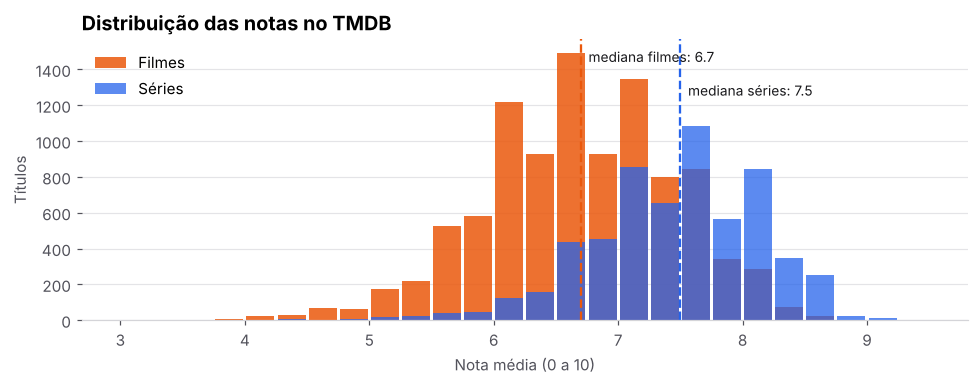

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(3, 9.6, 0.25)
ax.hist(df.loc[df.tipo == "Filme", "vote_average"].dropna(), bins=bins, color=LARANJA, alpha=0.85, label="Filmes", rwidth=0.9)
ax.hist(df.loc[df.tipo == "Série", "vote_average"].dropna(), bins=bins, color=AZUL, alpha=0.75, label="Séries", rwidth=0.9)
for tipo, cor in [("Filme", LARANJA), ("Série", AZUL)]:
    med = df.loc[df.tipo == tipo, "vote_average"].median()
    ax.axvline(med, color=cor, linewidth=1.5, linestyle="--")
    ax.annotate(f"mediana {tipo.lower()}s: {med:.1f}", (med, ax.get_ylim()[1] * (0.92 if tipo == "Filme" else 0.8)),
                xytext=(5, 0), textcoords="offset points", fontsize=9, color=TINTA)
ax.set_title("Distribuição das notas no TMDB")
ax.set_xlabel("Nota média (0 a 10)"); ax.set_ylabel("Títulos")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Palavras-chave

As palavras-chave do TMDB descrevem **temas** ("based on novel or book", "superhero", "time travel"). Elas são o segundo sinal mais forte do recomendador. Na limpeza, removemos as que só descrevem tom ("bold", "hilarious") ou detalhes técnicos ("aftercreditsstinger").

In [6]:
palavras = Counter(k for ks in df["keywords"] for k in ks)
print(f"{len(palavras):,} palavras-chave diferentes; média de {df['keywords'].str.len().mean():.1f} por título\n".replace(",", "."))
pd.DataFrame(palavras.most_common(15), columns=["palavra-chave", "títulos"])

19.703 palavras-chave diferentes; média de 9.2 por título



,palavra-chave,títulos
0,based on novel or book,1902
1,anime,1071
2,sequel,989
3,murder,869
4,romance,763
5,based on true story,684
6,new york city,615
7,friendship,613
8,based on manga,569
9,based on comic,518


## 2. Por que TF-IDF

Cada sinal (sinopse, palavras-chave, gêneros, pessoas, origem) vira um vetor **TF-IDF**. O **IDF** (*inverse document frequency*) dá **mais peso ao que é raro**:

$$\text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

Na prática, ter **Faroeste** em comum aproxima dois filmes muito mais do que ter **Drama** em comum. Esse ajuste resolveu, por exemplo, o caso de uma animação que recebia recomendações de filmes com atores reais.

In [7]:
filmes = [t for t in titulos if t["type"] == "MOVIE"]
mats_filmes = rec.matrizes(filmes)

from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer(analyzer=lambda x: x).fit([t["genres_compare"] for t in filmes])
pesos = pd.DataFrame({"gênero": vec.get_feature_names_out(), "idf": vec.idf_})
freq = Counter(g for t in filmes for g in t["genres_compare"])
pesos["% dos filmes"] = pesos["gênero"].map(lambda g: f"{freq[g] / len(filmes):.0%}")
pesos.sort_values("idf").round(2).set_index("gênero").iloc[[0, 1, 2, -4, -3, -2, -1]]

,idf,% dos filmes
gênero,,
Drama,1.84,43%
Comédia,2.05,35%
Thriller,2.31,27%
Música,4.65,3%
Faroeste,5.20,1%
Documentário,5.34,1%
Cinema TV,5.41,1%


## 3. O recomendador em ação

Para cada título, a similaridade com os outros do **mesmo tipo** é uma soma ponderada das similaridades de cosseno de cada sinal:

| Sinal | Peso |
|---|---|
| Sinopse | 0,30 |
| Palavras-chave | 0,25 |
| Gêneros | 0,25 |
| Pessoas (direção e elenco) | 0,12 |
| Origem (país e idioma) | 0,08 |

A ordem final soma ainda um **bônus de qualidade**: `0,80 · semelhança + 0,20 · qualidade`. Depois, o **filtro de franquias** é aplicado.

In [8]:
%%time
recomendacoes = rec.calcular_todos(titulos)
por_id = {t["id"]: t for t in titulos}

CPU times: user 7.23 s, sys: 152 ms, total: 7.38 s
Wall time: 7.4 s


In [9]:
def buscar(nome):
    achados = [t for t in titulos if nome.lower() in (t["title"].lower(), t["original_title"].lower())]
    return max(achados, key=lambda t: t["vote_count"])

def mostrar(nome, n=3):
    alvo = buscar(nome)
    linhas = []
    for rid, sim in recomendacoes[alvo["id"]][:n]:
        r = por_id[rid]
        linhas.append({"recomendação": f"{r['title']} ({r['year']})", "gêneros": ", ".join(r["genres"][:3]),
                       "nota": r["vote_average"], "semelhança": round(sim, 3)})
    tipo = "filme" if alvo["type"] == "MOVIE" else "série"
    print(f"{alvo['title']} ({alvo['year']}), {tipo}")
    return pd.DataFrame(linhas, index=range(1, n + 1))

mostrar("Um Sonho de Liberdade")

Um Sonho de Liberdade (1994), filme


,recomendação,gêneros,nota,semelhança
1,O Poderoso Chefão (1972),"Drama, Crime",8.7,0.343
2,Os Bons Companheiros (1990),"Drama, Crime",8.5,0.342
3,Prenda-Me se For Capaz (2002),"Drama, Crime",8.0,0.342


In [10]:
mostrar("Cidade de Deus")

Cidade de Deus (2002), filme


,recomendação,gêneros,nota,semelhança
1,Tropa de Elite (2007),"Drama, Ação, Crime",8.1,0.344
2,Os Donos da Rua (1991),"Drama, Crime",7.6,0.309
3,Um Sonho de Liberdade (1994),"Drama, Crime",8.7,0.263


In [11]:
mostrar("A Viagem de Chihiro")

A Viagem de Chihiro (2001), filme


,recomendação,gêneros,nota,semelhança
1,Meu Amigo Totoro (1988),"Fantasia, Animação, Família",8.1,0.382
2,O Serviço de Entregas da Kiki (1989),"Animação, Família, Fantasia",7.8,0.379
3,Mary e a Flor da Feiticeira (2017),"Animação, Aventura, Família",7.2,0.403


In [12]:
mostrar("Breaking Bad")

Breaking Bad (2008), série


,recomendação,gêneros,nota,semelhança
1,Better Call Saul (2015),"Crime, Drama",8.7,0.470
2,Narcos (2015),"Crime, Drama",8.1,0.387
3,Filhos da Anarquia (2008),"Crime, Drama",8.4,0.374


In [13]:
mostrar("Friends")

Friends (1994), série


,recomendação,gêneros,nota,semelhança
1,Como Eu Conheci Sua Mãe (2005),Comédia,8.1,0.445
2,Seinfeld (1989),Comédia,8.2,0.427
3,New Girl (2011),Comédia,7.4,0.438


## 4. Explicabilidade: de onde vem cada recomendação

Como a similaridade é uma soma de partes, dá para **explicar** cada recomendação: quanto cada sinal contribuiu para a nota final. Abaixo está a decomposição para *Um Sonho de Liberdade*.

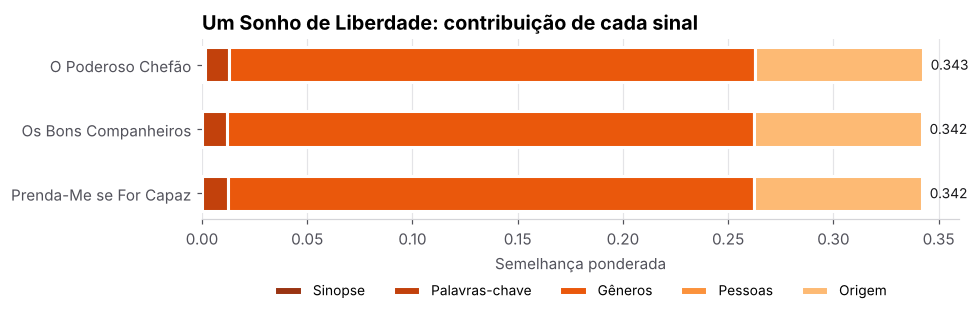

,sinopse,palavras,generos,pessoas,origem
O Poderoso Chefão,0.001,0.011,0.25,0.0,0.08
Os Bons Companheiros,0.000,0.012,0.25,0.0,0.08
Prenda-Me se For Capaz,0.000,0.012,0.25,0.0,0.08


In [14]:
def decompor(nome, n=3):
    alvo = buscar(nome)
    grupo = [t for t in titulos if t["type"] == alvo["type"]]
    mats = mats_filmes if alvo["type"] == "MOVIE" else rec.matrizes(grupo)
    pos = {t["id"]: i for i, t in enumerate(grupo)}
    i = pos[alvo["id"]]
    linhas = {}
    for rid, _ in recomendacoes[alvo["id"]][:n]:
        j = pos[rid]
        linhas[por_id[rid]["title"]] = {sinal: rec.PESOS[sinal] * (m[i] @ m[j].T).toarray()[0, 0]
                                        for sinal, m in mats.items()}
    return pd.DataFrame(linhas).T

contrib = decompor("Um Sonho de Liberdade")
nomes_sinais = {"sinopse": "Sinopse", "palavras": "Palavras-chave", "generos": "Gêneros", "pessoas": "Pessoas", "origem": "Origem"}
# Tons de uma só cor (laranja), do mais forte ao mais claro, com 2px de espaço entre segmentos
tons = ["#9A3412", "#C2410C", "#EA580C", "#FB923C", "#FDBA74"]

fig, ax = plt.subplots(figsize=(9, 3.2))
esquerda = np.zeros(len(contrib))
for sinal, cor in zip(contrib.columns, tons):
    ax.barh(contrib.index[::-1], contrib[sinal][::-1], left=esquerda[::-1], color=cor, height=0.55,
            edgecolor="white", linewidth=2, label=nomes_sinais[sinal])
    esquerda += contrib[sinal].to_numpy()
for y, (nome, total) in enumerate(zip(contrib.index[::-1], contrib.sum(axis=1)[::-1])):
    ax.annotate(f"{total:.3f}", (total, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Um Sonho de Liberdade: contribuição de cada sinal")
ax.set_xlabel("Semelhança ponderada")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
plt.tight_layout()
plt.show()
contrib.round(3)

### O que a decomposição revelou

Para *Um Sonho de Liberdade*, **quase toda a nota vem de gêneros e origem**: os três recomendados são dramas criminais americanos e muito bem avaliados. A sinopse e as palavras-chave quase não pesam.

O motivo é de **escala**. A similaridade de cosseno entre gêneros chega a 1,0 com facilidade (muitos filmes são exatamente "Drama, Crime"), enquanto a das sinopses raramente passa de 0,2, porque textos diferentes compartilham poucas palavras. Os pesos foram definidos como se os sinais tivessem a mesma escala, mas eles não têm.

A célula abaixo mede isso no catálogo inteiro.

In [15]:
def parcela_generos_origem(tipo, passo=7):
    grupo = [t for t in titulos if t["type"] == tipo]
    mats = mats_filmes if tipo == "MOVIE" else rec.matrizes(grupo)
    idx, _ = rec.vizinhos(grupo, 3)
    parcelas = []
    for i in range(0, len(grupo), passo):          # amostra de 1 a cada 7 títulos
        for j in idx[i]:
            partes = {k: rec.PESOS[k] * (m[i] @ m[j].T).toarray()[0, 0] for k, m in mats.items()}
            total = sum(partes.values())
            parcelas.append((partes["generos"] + partes["origem"]) / total if total else 0)
    return np.mean(parcelas)

for tipo, nome in [("MOVIE", "Filmes"), ("SHOW", "Séries")]:
    print(f"{nome}: {parcela_generos_origem(tipo):.0%} da semelhança das 3 primeiras recomendações vem de gêneros + origem")

Filmes: 86% da semelhança das 3 primeiras recomendações vem de gêneros + origem


Séries: 82% da semelhança das 3 primeiras recomendações vem de gêneros + origem


### Experimento: colocar os sinais na mesma escala

Uma correção simples é **normalizar cada sinal pelo seu valor máximo** para o título de referência: o título mais parecido em sinopse recebe 1,0 em sinopse, o mais parecido em gêneros recebe 1,0 em gêneros, e assim por diante. Só depois aplicamos os pesos.

A comparação abaixo mostra que a mudança **não é uma melhoria clara**: as recomendações ficam mais fiéis ao tema (prisão, jogos mortais, identidade), mas também mais obscuras e com alguns ruídos. Por isso, a versão publicada continua sendo a original, e calibrar os pesos com feedback real de usuários fica como próximo passo.

In [16]:
def recomendar_normalizado(nome, n=3):
    alvo = buscar(nome)
    grupo = [t for t in titulos if t["type"] == alvo["type"]]
    mats = mats_filmes if alvo["type"] == "MOVIE" else rec.matrizes(grupo)
    info = [franquias.preparar(t) for t in grupo]
    i = next(k for k, t in enumerate(grupo) if t["id"] == alvo["id"])
    sim = np.zeros(len(grupo), dtype=np.float32)
    for sinal, m in mats.items():
        s = (m[i] @ m.T).toarray()[0]
        s[i] = 0
        if s.max() > 0:
            s = s / s.max()                          # cada sinal passa a ir de 0 a 1
        sim += rec.PESOS[sinal] * s
    pontos = (1 - rec.PESO_QUALIDADE) * sim + rec.PESO_QUALIDADE * rec.qualidade(grupo)
    pontos[i] = -1
    escolhidos = []
    for j in np.argsort(-pontos):
        if franquias.mesma_franquia(info[i], info[j]) or any(franquias.mesma_franquia(info[k], info[j]) for k in escolhidos):
            continue
        escolhidos.append(j)
        if len(escolhidos) == n:
            break
    return [grupo[j]["title"] for j in escolhidos]

linhas = []
for nome in ["Um Sonho de Liberdade", "Clube da Luta", "Interestelar", "Parasita", "Round 6", "Breaking Bad"]:
    alvo = buscar(nome)
    atual = [por_id[r]["title"] for r, _ in recomendacoes[alvo["id"]][:3]]
    linhas.append({"título": nome, "versão publicada": " · ".join(atual),
                   "sinais normalizados": " · ".join(recomendar_normalizado(nome))})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(linhas).set_index("título")

,versão publicada,sinais normalizados
título,,
Um Sonho de Liberdade,O Poderoso Chefão · Os Bons Companheiros · Prenda-Me se For Capaz,Brubaker · Rebeldia Indomável · Golpe Baixo
Clube da Luta,Animais Noturnos · Brooklyn - Sem Pai Nem Mãe · Ponte dos Espiões,O Operário · Fargo: Uma Comédia de Erros · Seven - Os Sete Crimes Capitais
Interestelar,Perdido em Marte · A.I.: Inteligência Artificial · Devoradores de Estrelas,Atlantis: O Reino Perdido · Perdido em Marte · Cowboys do Espaço
Parasita,O Túnel · Memórias de um Assassino · A Única Saída,A Única Saída · Para Todos os Garotos: Agora e Para Sempre · Memórias de um Assassino
Round 6,Alice in Borderland · Em Movimento · As Três Irmãs,Alice in Borderland · Darwin's Game · The 8 Show
Breaking Bad,Better Call Saul · Narcos · Filhos da Anarquia,Better Call Saul · Metástasis · A Rainha do Sul


## 5. O filtro de franquias

Sem o filtro, o recomendador acerta "demais": quem gosta de *Toy Story* recebe *Toy Story 2, 3 e 5*, que a pessoa provavelmente já conhece. A regra (`pipeline/franquias.py`) considera dois títulos da mesma franquia quando:
- o **nome base** é igual (`"Toy Story 3"` → `"toy story"`);
- compartilham um **universo** do TMDB (como `"marvel cinematic universe (mcu)"`);
- o nome de um aparece no título do outro, ou os dois começam com as mesmas duas palavras, **e** há pessoas ou temas em comum. Exigir algo em comum evita confundir *Dark* com *Dark Matter*.

In [17]:
def antes_e_depois(nome, n=3):
    alvo = buscar(nome)
    grupo = [t for t in titulos if t["type"] == alvo["type"]]
    i = next(k for k, t in enumerate(grupo) if t["id"] == alvo["id"])
    idx, _ = rec.vizinhos(grupo, n)          # sem o filtro de franquias
    sem_filtro = [grupo[j]["title"] for j in idx[i]]
    com_filtro = [por_id[r]["title"] for r, _ in recomendacoes[alvo["id"]][:n]]
    return pd.DataFrame({"sem filtro": sem_filtro, "com filtro": com_filtro}, index=range(1, n + 1))

for nome in ["Toy Story: Um Mundo de Aventuras", "Vingadores: Ultimato", "Naruto"]:
    print(nome)
    display(antes_e_depois(nome))

Toy Story: Um Mundo de Aventuras


,sem filtro,com filtro
1,Toy Story 2,Carros
2,Toy Story 3,Zootopia: Essa Cidade é o Bicho
3,Toy Story 5,Vida de Inseto


Vingadores: Ultimato


,sem filtro,com filtro
1,Vingadores: Guerra Infinita,Liga da Justiça
2,Os Vingadores: The Avengers,X-Men: Dias de um Futuro Esquecido
3,Capitão América: Guerra Civil,A Máquina do Tempo


Naruto


,sem filtro,com filtro
1,Naruto Shippuden,Hell's Paradise
2,Boruto: Naruto Next Generations,Dragon Ball Z
3,Hell's Paradise,Black Clover


In [18]:
# Quantos títulos teriam ao menos uma recomendação (entre as 3 primeiras) da própria franquia sem o filtro?
afetados = {}
for tipo in ["MOVIE", "SHOW"]:
    grupo = [t for t in titulos if t["type"] == tipo]
    info = [franquias.preparar(t) for t in grupo]
    idx, _ = rec.vizinhos(grupo, 3)
    afetados[tipo] = np.mean([any(franquias.mesma_franquia(info[i], info[j]) for j in idx[i]) for i in range(len(grupo))])
print(f"Filmes: {afetados['MOVIE']:.1%} · Séries: {afetados['SHOW']:.1%} teriam recomendações da própria franquia sem o filtro")

Filmes: 20.5% · Séries: 9.9% teriam recomendações da própria franquia sem o filtro


## 6. Conclusões e limitações

**O que funcionou**
- A filtragem baseada em conteúdo funciona a partir de **um único título**, sem cadastro nem histórico (*cold start*).
- Combinar **cinco sinais** com TF-IDF dá recomendações coerentes em gêneros bem diferentes: drama prisional, anime, sitcom, thriller policial.
- O **IDF nos gêneros** e o **filtro de franquias** foram os dois ajustes que mais melhoraram a qualidade percebida.
- A soma ponderada é **explicável**: dá para mostrar por que cada título foi recomendado. Foi essa explicabilidade que revelou o principal ponto a melhorar (abaixo).

**Limitações**
- **Os sinais têm escalas diferentes**: gêneros e origem respondem por mais de 80% da semelhança, então as recomendações tendem a ser "títulos bem avaliados do mesmo gênero e país". O resultado é bom para o usuário, mas a sinopse e as palavras-chave contribuem menos do que os pesos sugerem.
- **Sem métrica offline**: a base não tem avaliações individuais, então a validação foi qualitativa.
- **O TF-IDF compara palavras, não significados**: "detetive" e "policial" contam como termos diferentes.
- O filtro de franquias **não detecta universos com nomes diferentes** (*Harry Potter* → *Animais Fantásticos*).
- Os **pesos foram definidos à mão**.

**Próximos passos**
1. **Calibrar a escala dos sinais** (normalização ou pesos aprendidos) e validar com testes A/B no site.
2. **Embeddings semânticos** (*sentence-transformers*) nas sinopses.
3. **Aprender os pesos** a partir de feedback (cliques ou avaliações no site).
4. **Modelo híbrido** com filtragem colaborativa (por exemplo, com o MovieLens).
5. Usar a **coleção** do TMDB (`belongs_to_collection`) para detectar franquias com nomes diferentes.

---
*Dados: [TMDB](https://www.themoviedb.org). Este produto usa a API do TMDB, mas não é endossado nem certificado pelo TMDB.*